**Data Cleaning**

In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Action(1): Handle Missing Values (Imputation)

In [3]:
df = pd.DataFrame({
    'EmployeeID': [101, 120, 111, 121, 157, 106, None],

    'Age': [25, None, 31, None, 40, 28, 30],

    'Gender': ['Male', None, 'Female', 'Male', 'Female', 'Male', 'Male'],

    'Department': ['IT', 'HR', 'IT', 'HR', 'IT', None, 'IT'],

    'Salary': [15000, 12000, None, 11000, None, 10000, 15000],

    # Bonus = Salary * 0.1, but some are missing
    'Bonus': [1500, None, None, 1100, None, 1000, 1500],

    # Notes = mostly null → to delete
    'Notes': [None, None, "Good performer", None, None, None, None]
})

df

,EmployeeID,Age,Gender,Department,Salary,Bonus,Notes
0,101.0,25.0,Male,IT,15000.0,1500.0,NaN
1,120.0,NaN,NaN,HR,12000.0,NaN,NaN
2,111.0,31.0,Female,IT,NaN,NaN,Good performer
3,121.0,NaN,Male,HR,11000.0,1100.0,NaN
4,157.0,40.0,Female,IT,NaN,NaN,NaN
5,106.0,28.0,Male,NaN,10000.0,1000.0,NaN
6,NaN,30.0,Male,IT,15000.0,1500.0,NaN


In [4]:
df.isnull().sum()

EmployeeID    1
Age           2
Gender        1
Department    1
Salary        2
Bonus         3
Notes         6
dtype: int64

In [5]:
df.isnull().mean()*100

EmployeeID    14.285714
Age           28.571429
Gender        14.285714
Department    14.285714
Salary        28.571429
Bonus         42.857143
Notes         85.714286
dtype: float64

Case 0: Drop rows contains null values

In [6]:
df.dropna(subset=['EmployeeID'], inplace=True)

Case 1: Imputing by mean

In [7]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

Case 2: Imputing by mode

In [8]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

Case 3: Add a new category to represent the null values

In [9]:
df['Department'] = df['Department'].fillna('Unknown')

Case 4: Imputing by mean/mode based on another categorical column

In [10]:
df['Salary'] = df['Salary'].fillna(df.groupby('Department')['Salary'].transform('mean'))

Case 5: Calculate the value of null values based on another column

In [11]:
df['Bonus'] = df['Bonus'].fillna(df['Salary'] * 0.1)

Case 6: Remove the entire column

In [12]:
df.drop(columns='Notes', inplace=True)

Final result

In [13]:
df.isnull().sum()

EmployeeID    0
Age           0
Gender        0
Department    0
Salary        0
Bonus         0
dtype: int64

In [14]:
df.head()

,EmployeeID,Age,Gender,Department,Salary,Bonus
0,101.0,25.0,Male,IT,15000.0,1500.0
1,120.0,31.0,Male,HR,12000.0,1200.0
2,111.0,31.0,Female,IT,15000.0,1500.0
3,121.0,31.0,Male,HR,11000.0,1100.0
4,157.0,40.0,Female,IT,15000.0,1500.0


Another Example for handling missing Datausing different imputation methods

In [15]:
df_time = pd.DataFrame({
    'Date': pd.date_range(start='2025-11-10', periods=7, freq='D'),

    'Temperature': [30, None, 32, None, None, 28, 29],

    'Sales': [200, None, None, 250, None, None, 300],
})

df_time

,Date,Temperature,Sales
0,2025-11-10,30.0,200.0
1,2025-11-11,NaN,NaN
2,2025-11-12,32.0,NaN
3,2025-11-13,NaN,250.0
4,2025-11-14,NaN,NaN
5,2025-11-15,28.0,NaN
6,2025-11-16,29.0,300.0


In [17]:
# Temperature: forward fill
df_time['Temperature'] = df_time['Temperature'].ffill()

# Sales: backfill
df_time['Sales'] = df_time['Sales'].bfill()

In [18]:
df_time

,Date,Temperature,Sales
0,2025-11-10,30.0,200.0
1,2025-11-11,30.0,250.0
2,2025-11-12,32.0,250.0
3,2025-11-13,32.0,250.0
4,2025-11-14,32.0,300.0
5,2025-11-15,28.0,300.0
6,2025-11-16,29.0,300.0


Action(2): Handle Duplicated Values

In [19]:
df_dup = pd.DataFrame({
    'EmployeeID': [101, 102, 103, 101, 104, 102],
    'Name': ['Ali', 'Sara', 'Mona', 'Ali', 'Omar', 'Sara'],
    'Department': ['IT', 'HR', 'IT', 'IT', 'Finance', 'HR'],
    'Salary': [15000, 12000, 15000, 15000, 11000, 12000]
})

df_dup

,EmployeeID,Name,Department,Salary
0,101,Ali,IT,15000
1,102,Sara,HR,12000
2,103,Mona,IT,15000
3,101,Ali,IT,15000
4,104,Omar,Finance,11000
5,102,Sara,HR,12000


Case 1: Drop all duplicate rows

In [20]:
df_no_dup = df_dup.drop_duplicates()

Case 2: Drop duplicates based on a subset of columns

In [21]:
df_no_dup_subset = df_dup.drop_duplicates(subset=['EmployeeID', 'Name'])

In [22]:
df.head()

,EmployeeID,Age,Gender,Department,Salary,Bonus
0,101.0,25.0,Male,IT,15000.0,1500.0
1,120.0,31.0,Male,HR,12000.0,1200.0
2,111.0,31.0,Female,IT,15000.0,1500.0
3,121.0,31.0,Male,HR,11000.0,1100.0
4,157.0,40.0,Female,IT,15000.0,1500.0


Action(3): Removing the Outliers

In [23]:
df_outlier = pd.DataFrame({
    'EmployeeID': [101, 102, 103, 104, 105, 106, 107],
    'Salary': [15000, 12000, 13000, 200000, 11000, 12500, 300000],
    'Age': [25, 30, 28, 27, 26, 29, 22]
})


In [24]:
df_outlier

,EmployeeID,Salary,Age
0,101,15000,25
1,102,12000,30
2,103,13000,28
3,104,200000,27
4,105,11000,26
5,106,12500,29
6,107,300000,22


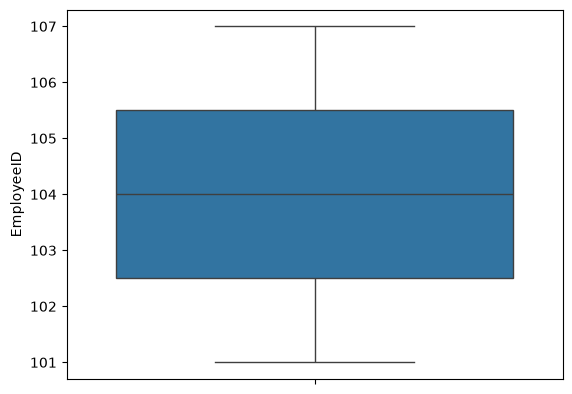

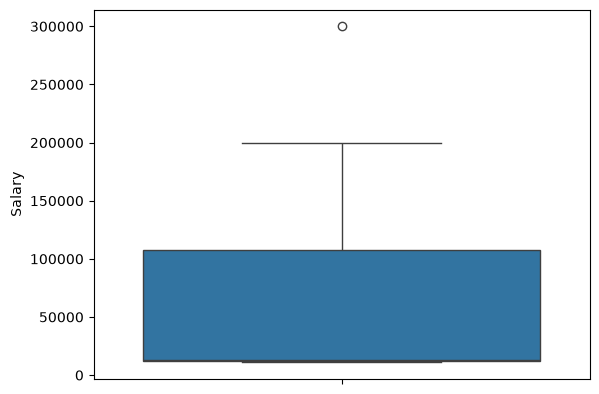

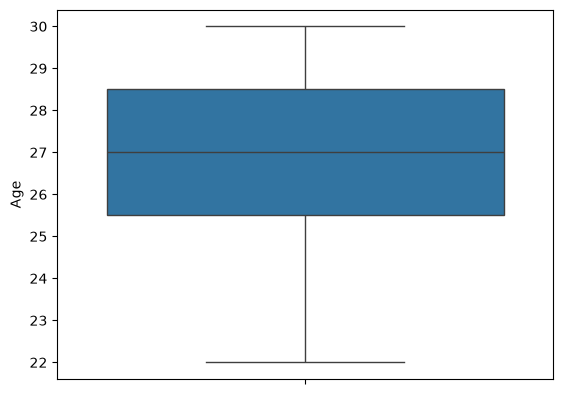

In [25]:
for col in df_outlier.columns:
  sns.boxplot(df_outlier[col])
  plt.show()

In [26]:
Q1 = df_outlier['Salary'].quantile(0.25)
Q3 = df_outlier['Salary'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f"Salary lower bound: {lower_bound}, upper bound: {upper_bound}")

Salary lower bound: 0, upper bound: 250375.0


In [27]:
df_no_outliers = df_outlier[(df_outlier['Salary'] >= lower_bound) & (df_outlier['Salary'] <= upper_bound)]

In [28]:
df_no_outliers

,EmployeeID,Salary,Age
0,101,15000,25
1,102,12000,30
2,103,13000,28
3,104,200000,27
4,105,11000,26
5,106,12500,29


**EDA**

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Use Case 1: Chack The Datatypes

Goal-> Make sure every column has the correct data type — because wrong types can cause errors or incorrect calculations later.

In [30]:
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': ['25', 'None', '30'],
    'Salary': ['$4000', '$3500', '$5000'],
    'Phone': ['+1-202-555-0182', '202-555-0176', '202-555-0198']
}

df = pd.DataFrame(data)
df.head()

,Name,Age,Salary,Phone
0,Alice,25,$4000,+1-202-555-0182
1,Bob,None,$3500,202-555-0176
2,Charlie,30,$5000,202-555-0198


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Name    3 non-null      str  
 1   Age     3 non-null      str  
 2   Salary  3 non-null      str  
 3   Phone   3 non-null      str  
dtypes: str(4)
memory usage: 305.0 bytes


In [32]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [33]:
df.head()

,Name,Age,Salary,Phone
0,Alice,25.0,$4000,+1-202-555-0182
1,Bob,NaN,$3500,202-555-0176
2,Charlie,30.0,$5000,202-555-0198


In [34]:
df['Salary'] = df['Salary'].str.strip('$')
df['Salary'] = df['Salary'].astype('float')

In [35]:
df['Phone'] = df['Phone'].str.strip('+1')
df['Phone'] = df['Phone'].str.replace('-','')
df['Phone'] = df['Phone'].str.replace(' ','')
# df['Phone'] = df['Phone'].str.replace(r'\D', '', regex=True)
df['Phone'] = df['Phone'].astype('int')

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    3 non-null      str    
 1   Age     2 non-null      float64
 2   Salary  3 non-null      float64
 3   Phone   3 non-null      int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 243.0 bytes


In [37]:
df.head()

,Name,Age,Salary,Phone
0,Alice,25.0,4000.0,2025550182
1,Bob,NaN,3500.0,2025550176
2,Charlie,30.0,5000.0,2025550198


Use Case 2: Validate Numerical Ranges

In [38]:
data = {
    'Name': ['Alice', 'Charlie', 'Dina', 'Ethan'],
    'Rating(stars)': [4.5, 5, 6, 3],
    'Age': [25, 40, -20, 28]
}

df = pd.DataFrame(data)
df.head()

,Name,Rating(stars),Age
0,Alice,4.5,25
1,Charlie,5.0,40
2,Dina,6.0,-20
3,Ethan,3.0,28


In [39]:
df.describe()

,Rating(stars),Age
count,4.000,4.000000
mean,4.625,18.250000
std,1.250,26.310644
min,3.000,-20.000000
25%,4.125,13.750000
50%,4.750,26.500000
75%,5.250,31.000000
max,6.000,40.000000


In [40]:
len(df[df['Rating(stars)']>5])

1

In [41]:
df['Age'] = df['Age'].apply('abs')

In [42]:
df['Rating(stars)'].replace(6, 5, inplace=True)
df['Rating(stars)'] = df['Rating(stars)'].replace(6, 5)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24080\137559430.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Rating(stars)'].replace(6, 5, inplace=True)


In [43]:
df.head()

,Name,Rating(stars),Age
0,Alice,4.5,25
1,Charlie,5.0,40
2,Dina,5.0,20
3,Ethan,3.0,28


Use Case 3: Incpect Unique Categories

In [44]:
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'Dina', 'Ethan', 'Fatma', 'George'],
    'Gender': ['Female', 'Female', 'F', 'Woman', 'Male', 'M', 'Man'],
    'Subscribed': ['Yes', 'no', 'YES', 'No', 'yes', 'No', 'nO'],          # different capitalization
}

df = pd.DataFrame(data)
df.head()

,Name,Gender,Subscribed
0,Alice,Female,Yes
1,Bob,Female,no
2,Charlie,F,YES
3,Dina,Woman,No
4,Ethan,Male,yes


In [45]:
df.describe(include='object')

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24080\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Name,Gender,Subscribed
count,7,7,7
unique,7,6,6
top,Alice,Female,No
freq,1,2,2


In [46]:
df['Subscribed'].unique()

<ArrowStringArray>
['Yes', 'no', 'YES', 'No', 'yes', 'nO']
Length: 6, dtype: str

In [47]:
df['Subscribed'] = df['Subscribed'].str.upper()

In [48]:
df['Subscribed'].unique()

<ArrowStringArray>
['YES', 'NO']
Length: 2, dtype: str

In [49]:
df['Gender'].unique()

<ArrowStringArray>
['Female', 'F', 'Woman', 'Male', 'M', 'Man']
Length: 6, dtype: str

In [50]:
genders = {'F': 'Female',
           'Woman': 'Female',
           'M': 'Male',
           'Man': 'Male'}

df['Gender'] = df['Gender'].replace(genders)

In [51]:
df['Gender'].unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Use Case 4: Chack For Missing Values

In [52]:
data = {
    'Name': ['Alice', 'Bob', np.nan, 'Dina', 'Ethan', 'Fatma'],
    'Age': [25, np.nan, 'None', 30, '', 28],
    'Salary': [4000, 3500, np.nan, 'None', 4200, 3900],
    'Department': ['HR', '', '', np.nan, 'None', 'Finance']
}

df = pd.DataFrame(data)
df.head()

,Name,Age,Salary,Department
0,Alice,25,4000,HR
1,Bob,NaN,3500,
2,NaN,None,NaN,
3,Dina,30,None,NaN
4,Ethan,,4200,None


In [53]:
df.isnull() #or isna

,Name,Age,Salary,Department
0,False,False,False,False
1,False,True,False,False
2,True,False,True,False
3,False,False,False,True
4,False,False,False,False
5,False,False,False,False


In [54]:
df.isnull().sum()

Name          1
Age           1
Salary        1
Department    1
dtype: int64

In [55]:
df['Department'].unique()

<ArrowStringArray>
['HR', '', nan, 'None', 'Finance']
Length: 5, dtype: str

In [56]:
df = df.replace(['None', ''], np.nan)

In [57]:
df.isnull().sum()

Name          1
Age           3
Salary        2
Department    4
dtype: int64

In [58]:
df.isnull().mean()*100

Name          16.666667
Age           50.000000
Salary        33.333333
Department    66.666667
dtype: float64

In [59]:
df.isna().all(axis=1)

0    False
1    False
2     True
3    False
4    False
5    False
dtype: bool

In [60]:
df.isna().all(axis=1).sum()

np.int64(1)

In [61]:
all_null_rows = df.isnull().all(axis=1)
all_null_rows = df.index[all_null_rows].tolist()
all_null_rows

[2]

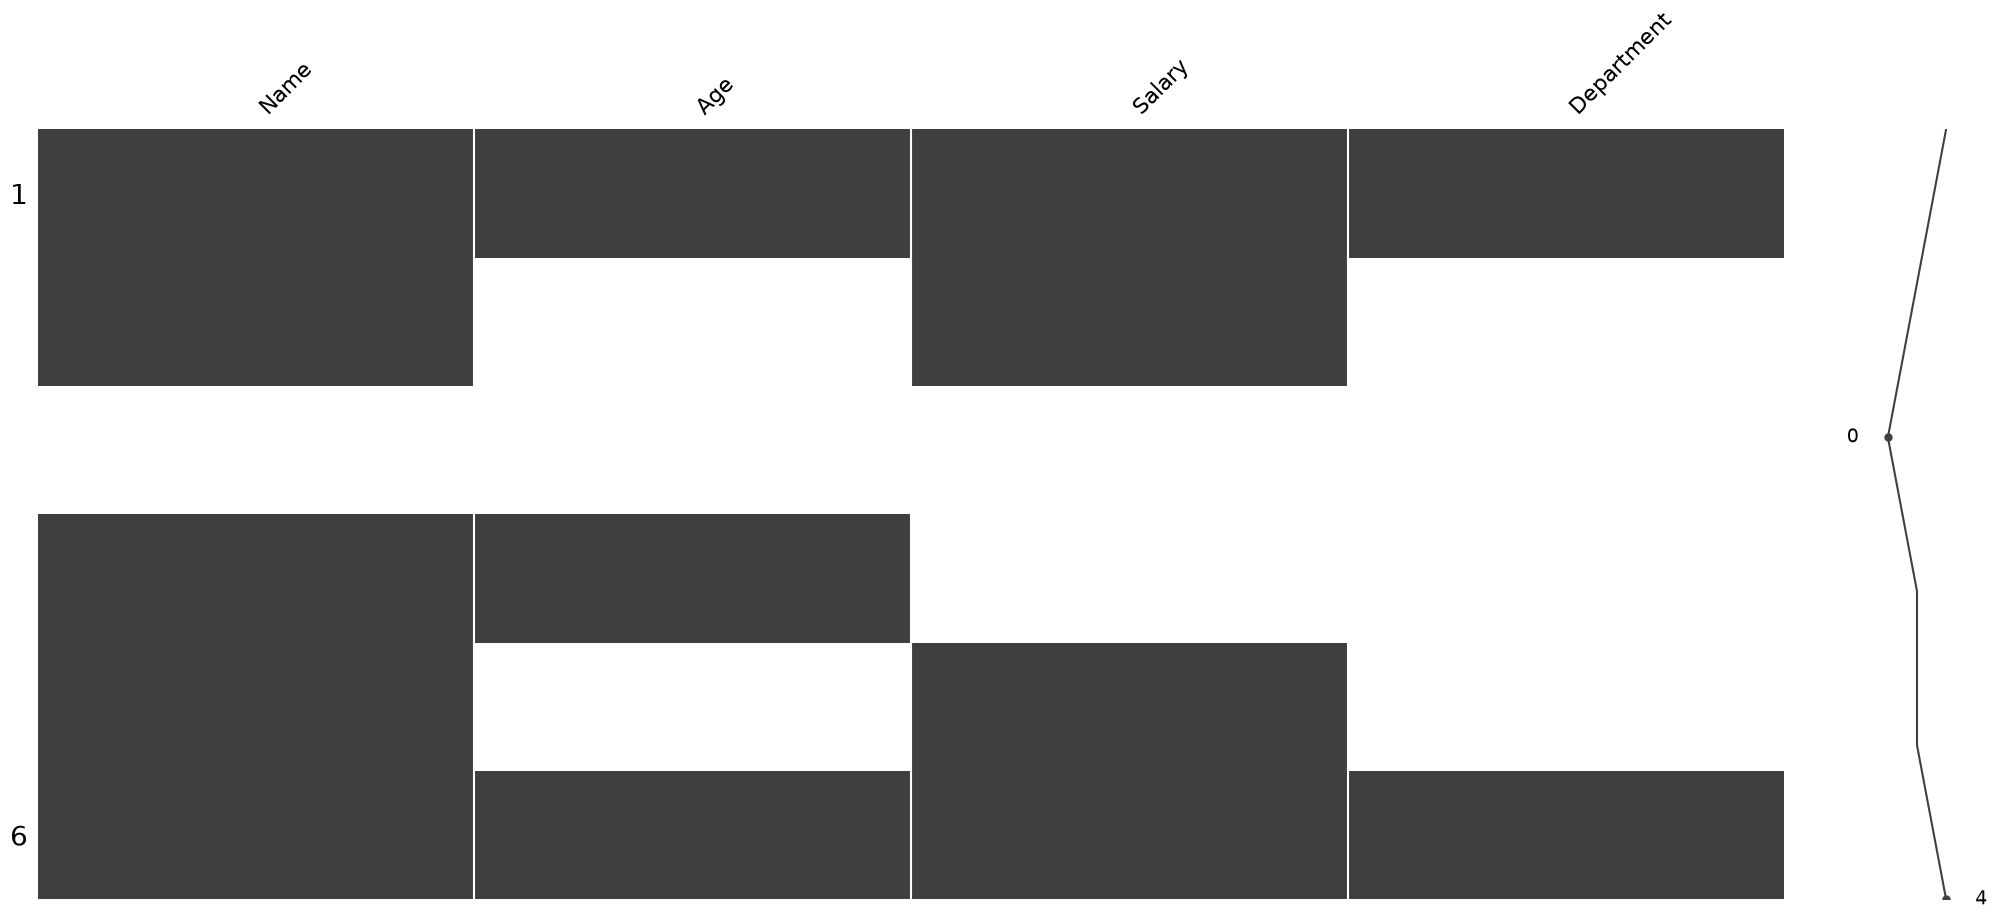

In [63]:
import missingno as msno
msno.matrix(df)
plt.show()

Use Case 5: Chack For Duplicates

In [64]:
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'Alice', 'Dina', 'Bob'],
    'Age': [25, 30, 35, 25, 28, 30],
    'Salary': [4000, 3500, 5000, 4000, 4200, 3500],
    'Department': ['HR', 'IT', 'Finance', 'HR', 'IT', 'IT']
}

df = pd.DataFrame(data)
df

,Name,Age,Salary,Department
0,Alice,25,4000,HR
1,Bob,30,3500,IT
2,Charlie,35,5000,Finance
3,Alice,25,4000,HR
4,Dina,28,4200,IT
5,Bob,30,3500,IT


In [65]:
df.duplicated()

0    False
1    False
2    False
3     True
4    False
5     True
dtype: bool

In [66]:
df.duplicated(keep=False)

0     True
1     True
2    False
3     True
4    False
5     True
dtype: bool

In [67]:
duplicates = df.duplicated(keep=False)
df[duplicates]

,Name,Age,Salary,Department
0,Alice,25,4000,HR
1,Bob,30,3500,IT
3,Alice,25,4000,HR
5,Bob,30,3500,IT


In [68]:
df.duplicated().sum()

np.int64(2)

In [69]:
df['ID'] = [1, 2, 3, 4, 5, 6]

In [70]:
df.head(6)

,Name,Age,Salary,Department,ID
0,Alice,25,4000,HR,1
1,Bob,30,3500,IT,2
2,Charlie,35,5000,Finance,3
3,Alice,25,4000,HR,4
4,Dina,28,4200,IT,5
5,Bob,30,3500,IT,6


In [71]:
df.duplicated().sum()

np.int64(0)

In [72]:
df.duplicated(subset=['ID','Name'])

0    False
1    False
2    False
3    False
4    False
5    False
dtype: bool

In [73]:
df.duplicated(subset=['Name']).sum()

np.int64(2)

In [74]:
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'Dina', 'Ethan', 'Fatma', 'George'],
    'Age': [25, 30, 35, 28, 200, 27, 29],
    'Salary': [4000, 3500, 5000, 4200, 3800, 100000, 3900],
    'Rating': [4.5, 5, 5, 4, 3, 5, 3]
}

df = pd.DataFrame(data)
df

,Name,Age,Salary,Rating
0,Alice,25,4000,4.5
1,Bob,30,3500,5.0
2,Charlie,35,5000,5.0
3,Dina,28,4200,4.0
4,Ethan,200,3800,3.0
5,Fatma,27,100000,5.0
6,George,29,3900,3.0


In [75]:
df.describe()

,Age,Salary,Rating
count,7.000000,7.000000,7.000000
mean,53.428571,17771.428571,4.214286
std,64.706664,36262.410027,0.906327
min,25.000000,3500.000000,3.000000
25%,27.500000,3850.000000,3.500000
50%,29.000000,4000.000000,4.500000
75%,32.500000,4600.000000,5.000000
max,200.000000,100000.000000,5.000000


In [76]:
numeric_cols = ['Age', 'Salary', 'Rating']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"Outliers in {col}:")
    print(outliers[[col]])
    print("-"*30)


Outliers in Age:
   Age
4  200
------------------------------
Outliers in Salary:
   Salary
5  100000
------------------------------
Outliers in Rating:
Empty DataFrame
Columns: [Rating]
Index: []
------------------------------


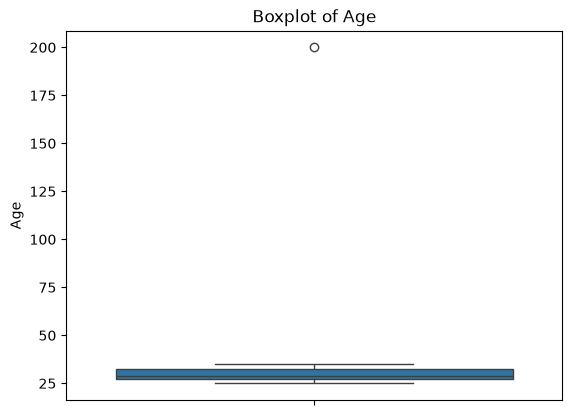

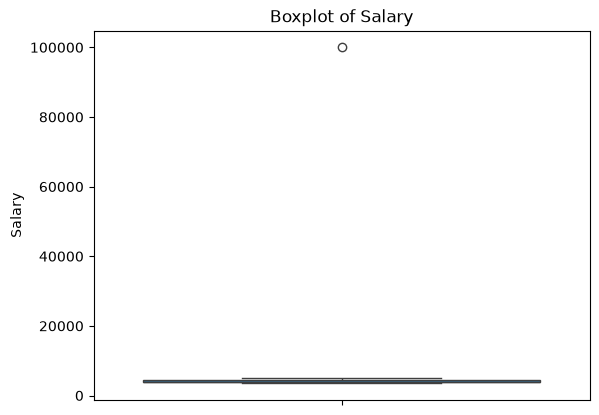

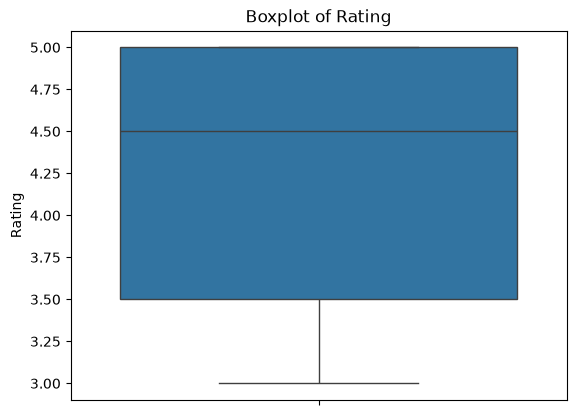

In [77]:
for col in numeric_cols:
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

Use Case 7: Explore Distributions

Understand the frequency, spread, and shape of each variable.

In [78]:

data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'Dina', 'Ethan', 'Fatma', 'Ahmed', 'Hana', 'Ibrahim', 'Jana'],
    'Age': [25, 30, 35, 28, 32, 27, 29, 31, 40, 26],
    'Salary': [4000, 3500, 5000, 4200, 3800, 3900, 4100, 4300, 4800, 3700],
    'Rating': [4, 5, 4, 3, 5, 4, 3, 5, 4, 3],
    'Department': ['HR', 'IT', 'Finance', 'HR', 'IT', 'Finance', 'IT', 'HR', 'Finance', 'IT']
}

df = pd.DataFrame(data)
df

,Name,Age,Salary,Rating,Department
0,Alice,25,4000,4,HR
1,Bob,30,3500,5,IT
2,Charlie,35,5000,4,Finance
3,Dina,28,4200,3,HR
4,Ethan,32,3800,5,IT
5,Fatma,27,3900,4,Finance
6,Ahmed,29,4100,3,IT
7,Hana,31,4300,5,HR
8,Ibrahim,40,4800,4,Finance
9,Jana,26,3700,3,IT


In [79]:
df.describe()

,Age,Salary,Rating
count,10.000000,10.000000,10.000000
mean,30.300000,4130.000000,4.000000
std,4.522782,471.522357,0.816497
min,25.000000,3500.000000,3.000000
25%,27.250000,3825.000000,3.250000
50%,29.500000,4050.000000,4.000000
75%,31.750000,4275.000000,4.750000
max,40.000000,5000.000000,5.000000


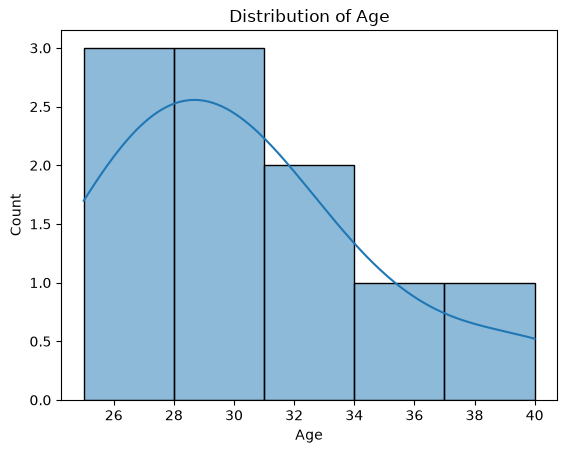

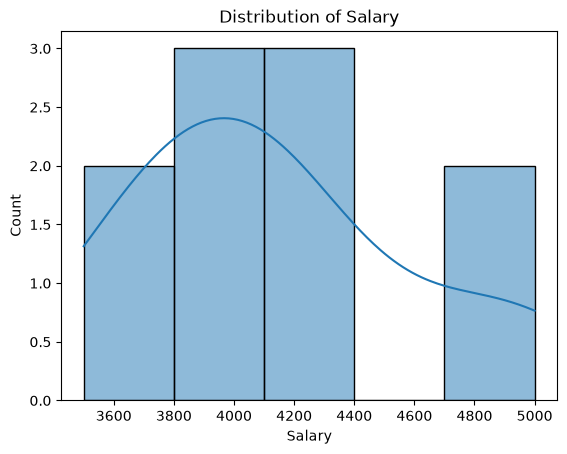

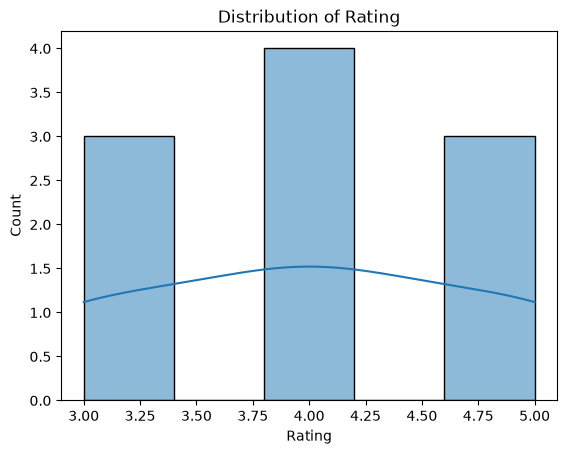

In [80]:
numeric_cols = ['Age', 'Salary', 'Rating']

for col in numeric_cols:
    sns.histplot(df[col], kde=True, bins=5)
    plt.title(f"Distribution of {col}")
    plt.show()

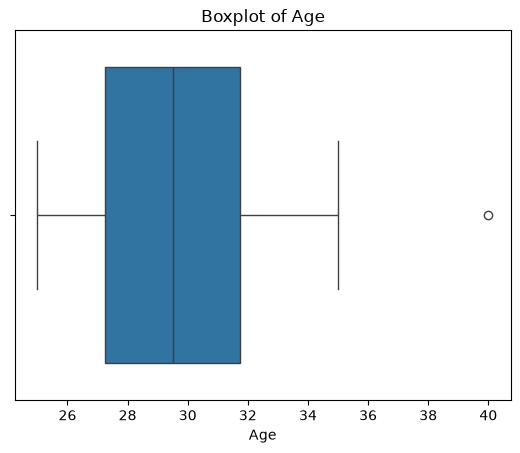

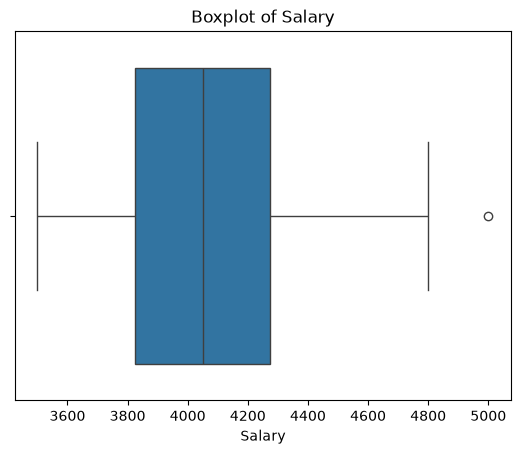

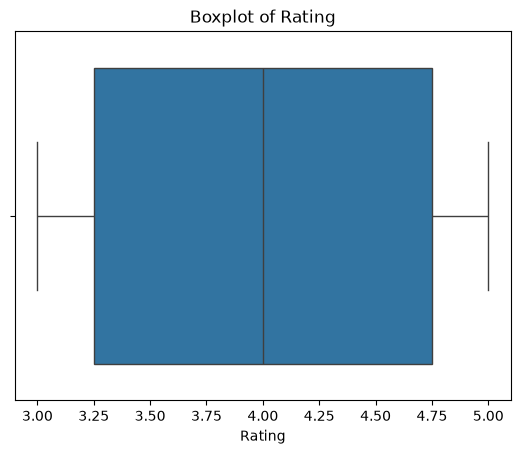

In [81]:
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


Use Case 8: Explore Relationships

1- Numeric vs Numeric — Correlation

             Age    Salary    Rating
Age     1.000000  0.703890  0.300883
Salary  0.703890  1.000000 -0.115441
Rating  0.300883 -0.115441  1.000000


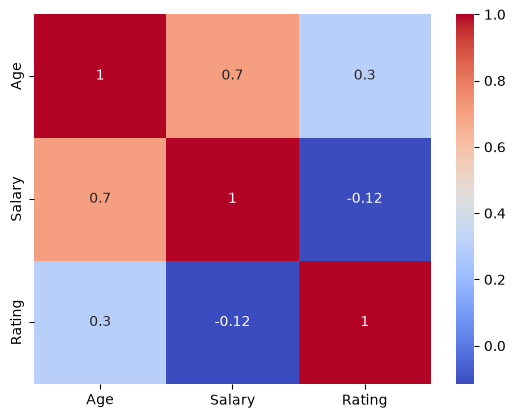

In [82]:
corr = df[numeric_cols].corr()
print(corr)

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

2- Numeric vs Categorical — Boxplots

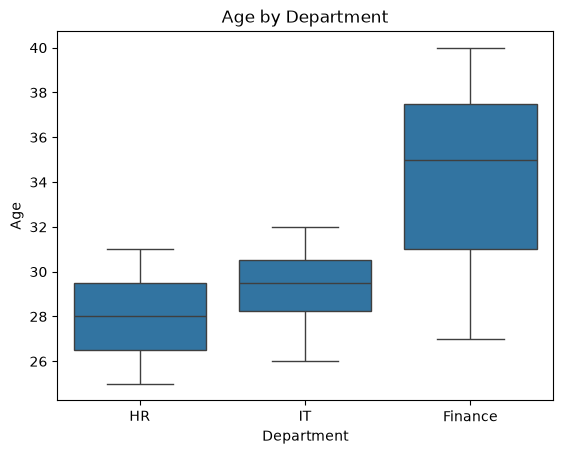

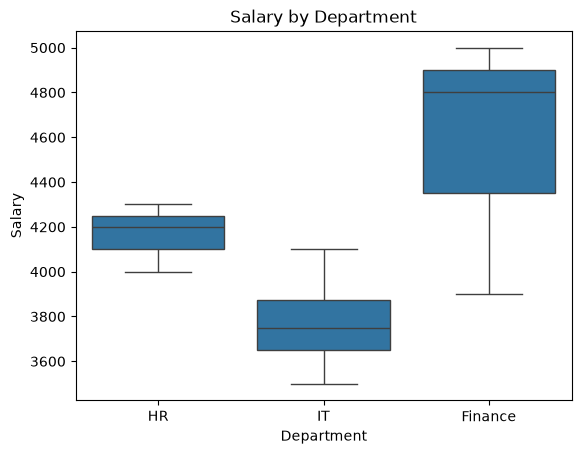

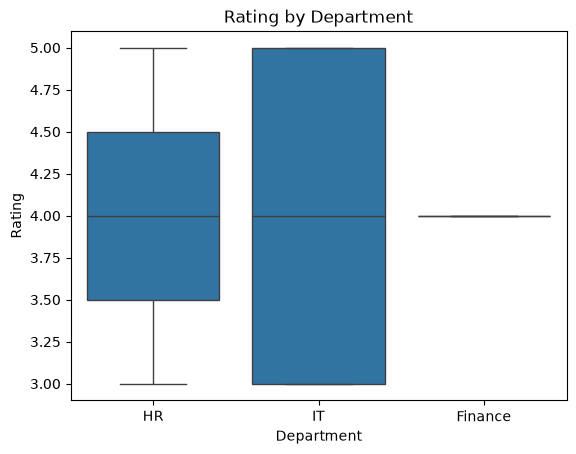

In [83]:
for col in numeric_cols:
    sns.boxplot(x=df['Department'], y=df[col])
    plt.title(f"{col} by Department")
    plt.show()

3- Categorical vs Categorical - Countplot

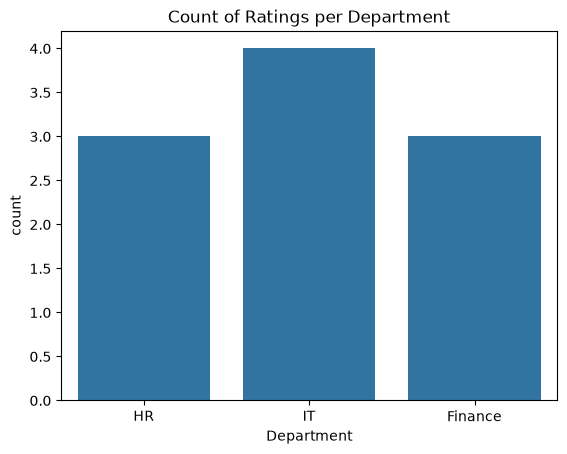

In [84]:
sns.countplot(x='Department', data=df)
plt.title("Count of Ratings per Department")
plt.show()

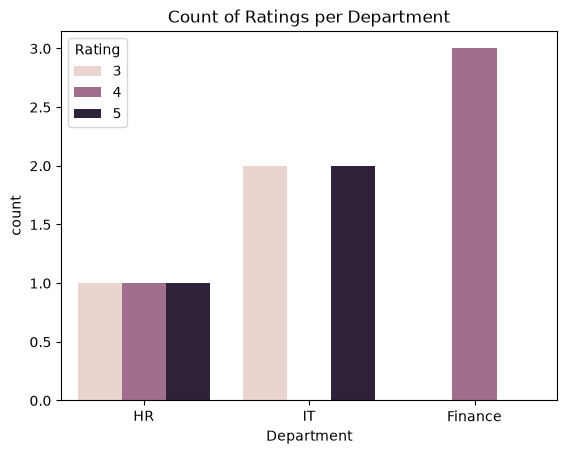

In [85]:
sns.countplot(x='Department', hue='Rating', data=df)
plt.title("Count of Ratings per Department")
plt.show()